In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
df = pd.read_csv("creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()
df[["Time", "Amount"]] = scaler.fit_transform(df[["Time", "Amount"]])
X = df.drop("Class", axis=1).values
y = df["Class"].values
print(X.shape, y.shape)

(284807, 30) (284807,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train fraud:", y_train.sum(), "| Test fraud:", y_test.sum())

Train fraud: 394 | Test fraud: 98


In [ ]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print(class_weight)

{0: np.float64(0.5008661206149896), 1: np.float64(289.14340101522845)}


In [ ]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
print("Baseline trained")

Baseline trained


In [ ]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=keras.optimizers.Adam(0.001),
              loss="binary_crossentropy",
              metrics=["AUC"])
model.summary()

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=2048,
                    validation_split=0.2,
                    class_weight=class_weight, verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - AUC: 0.6669 - loss: 0.7004 - val_AUC: 0.9261 - val_loss: 0.4766
Epoch 2/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.9137 - loss: 0.3890 - val_AUC: 0.9613 - val_loss: 0.3423
Epoch 3/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9418 - loss: 0.3017 - val_AUC: 0.9755 - val_loss: 0.2226
Epoch 4/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9610 - loss: 0.2507 - val_AUC: 0.9843 - val_loss: 0.1626
Epoch 5/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9628 - loss: 0.2281 - val_AUC: 0.9860 - val_loss: 0.1369
Epoch 6/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9711 - loss: 0.1964 - val_AUC: 0.9864 - val_loss: 0.1175
Epoch 7/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9755 - loss: 0.1922 - val_AUC: 0.9870 - val_loss: 0.1102
Epoch 8/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9805 - loss: 0.1690 - val_AUC: 0.9881 - val_loss: 0.1022
Epoch 9/20
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.9807 - loss:

In [ ]:
ann_prob = model.predict(X_test).ravel()
print(ann_prob[:5])

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
[0.00440161 0.01000482 0.03032532 0.00312364 0.9053203 ]


In [ ]:
def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    print(f"=== {name} (threshold={threshold}) ===")
    print(classification_report(y_true, pred, digits=4))
    print("ROC-AUC:", roc_auc_score(y_true, prob))
    print("PR-AUC :", average_precision_score(y_true, prob))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred)).plot()
    plt.title(name)
    plt.show()

=== Logistic Regression (threshold=0.5) ===
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0609    0.9184    0.1141        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5509     56962
weighted avg     0.9982    0.9755    0.9861     56962

ROC-AUC: 0.9721669425367221
PR-AUC : 0.7189463752156903


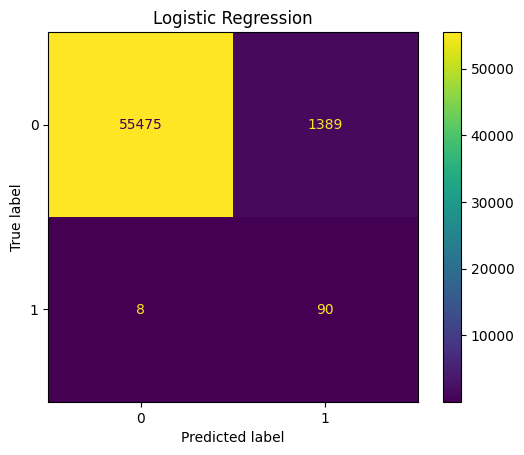

=== ANN (MLP) (threshold=0.5) ===
              precision    recall  f1-score   support

           0     0.9999    0.9812    0.9905     56864
           1     0.0778    0.9184    0.1434        98

    accuracy                         0.9811     56962
   macro avg     0.5388    0.9498    0.5669     56962
weighted avg     0.9983    0.9811    0.9890     56962

ROC-AUC: 0.9776790200463978
PR-AUC : 0.6888301340504701


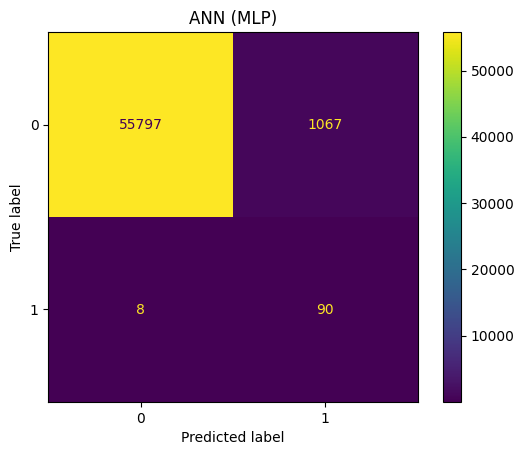

In [ ]:
evaluate("Logistic Regression", y_test, lr_prob)
evaluate("ANN (MLP)", y_test, ann_prob)

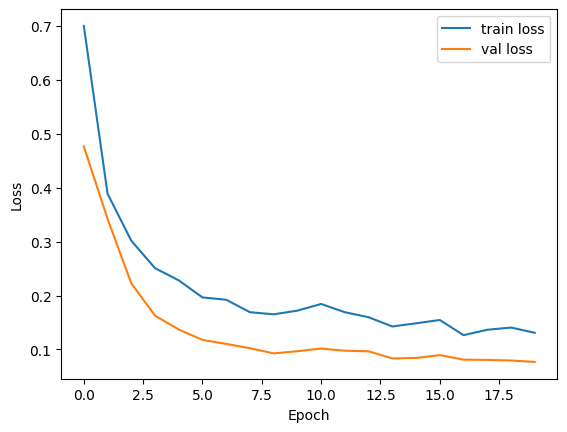

In [ ]:
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
def recommend(p):
    if p >= 0.90:
        return "HIGH RISK: Block transaction and contact cardholder"
    elif p >= 0.50:
        return "MEDIUM RISK: Ask for OTP / extra verification"
    else:
        return "LOW RISK: Allow transaction"

for p in ann_prob[:5]:
    print(round(float(p), 4), "->", recommend(p))

0.0044 -> LOW RISK: Allow transaction
0.01 -> LOW RISK: Allow transaction
0.0303 -> LOW RISK: Allow transaction
0.0031 -> LOW RISK: Allow transaction
0.9053 -> HIGH RISK: Block transaction and contact cardholder


In [ ]:
fraud_idx = np.where(y_test == 1)[0][:5]
for i in fraud_idx:
    print(round(float(ann_prob[i]), 4), "->", recommend(ann_prob[i]))

1.0 -> HIGH RISK: Block transaction and contact cardholder
1.0 -> HIGH RISK: Block transaction and contact cardholder
1.0 -> HIGH RISK: Block transaction and contact cardholder
0.9991 -> HIGH RISK: Block transaction and contact cardholder
1.0 -> HIGH RISK: Block transaction and contact cardholder


In [ ]:
for t in [0.5, 0.7, 0.9, 0.95, 0.99]:
    pred = (ann_prob >= t).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    fn = ((pred == 0) & (y_test == 1)).sum()
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn)
    print(f"threshold={t}: precision={prec:.4f}, recall={rec:.4f}, false alarms={fp}")

threshold=0.5: precision=0.0778, recall=0.9184, false alarms=1067
threshold=0.7: precision=0.1740, recall=0.8878, false alarms=413
threshold=0.9: precision=0.4503, recall=0.8776, false alarms=105
threshold=0.95: precision=0.6562, recall=0.8571, false alarms=44
threshold=0.99: precision=0.7257, recall=0.8367, false alarms=31


In [ ]:
model.save("fraud_ann.keras")
from google.colab import files
files.download("fraud_ann.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q gradio
import gradio as gr

def check(kind, index):
    if kind == "Random genuine transaction":
        i = int(np.random.choice(np.where(y_test == 0)[0]))
    elif kind == "Random fraud transaction":
        i = int(np.random.choice(np.where(y_test == 1)[0]))
    else:
        i = int(index)
    p = float(model.predict(X_test[i:i+1], verbose=0)[0][0])
    actual = "FRAUD" if y_test[i] == 1 else "GENUINE"
    return f"Test row #{i}", f"{p:.4f}", recommend(p), actual

demo = gr.Interface(
    fn=check,
    inputs=[
        gr.Radio(["Random genuine transaction", "Random fraud transaction", "Choose row number"],
                 value="Random fraud transaction", label="Select transaction"),
        gr.Number(value=0, precision=0, label="Row number (0 to 56961, only for 'Choose row number')"),
    ],
    outputs=[
        gr.Textbox(label="Transaction"),
        gr.Textbox(label="Fraud probability (ANN)"),
        gr.Textbox(label="Safety recommendation"),
        gr.Textbox(label="Actual label"),
    ],
    title="Credit Card Fraud Detection using ANN",
    description="Pick a test transaction. The ANN predicts the fraud probability and gives a safety recommendation.",
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d761acf3a8923b23d3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
